In [1]:
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l


### Neural Architecture Search (NAS)
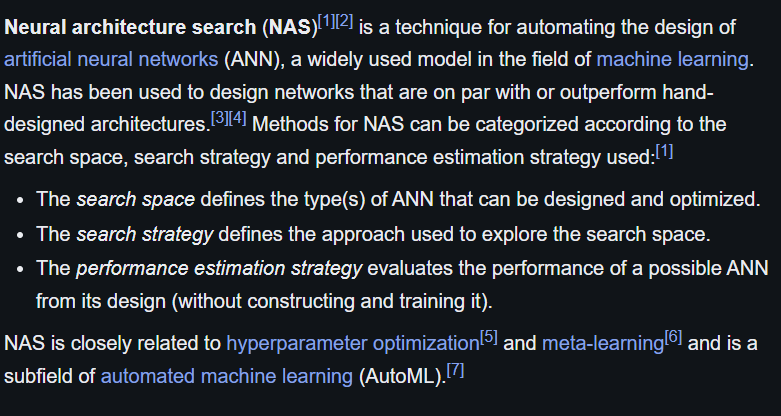

Every architecture we have discussed so far—from GoogLeNet’s parallel branches to ResNet’s skip connections and DenseNet’s dense concatenations—was painstakingly hand-crafted by human researchers relying on intuition, trial and error, and heuristics.

Neural Architecture Search (NAS) flips this paradigm completely: it treats the design of the neural network itself as a machine learning optimization problem. Instead of humans designing the network to learn the data, we use algorithms to learn the optimal network design.

A complete NAS system is built upon three mathematically and computationally distinct pillars.

### 1. The Search Space (The Architectural Vocabulary)

Before the algorithm can search, we must define exactly what it is allowed to build. If the search space is unbounded, the problem is computationally impossible to solve.

* **Macro-Search Spaces:** The algorithm builds the entire network layer by layer from scratch. It chooses the operation (e.g., $3 \times 3$ conv, max pooling, identity), the number of filters, and where to route the skip connections for every single step. This is incredibly expensive.
* **Micro (Cell-Based) Search Spaces:** Inspired by ResNet and GoogLeNet, researchers realized that good networks are just a single, highly optimized "block" (or cell) repeated many times. In a cell-based search space, the algorithm only designs two small motifs: a **Normal Cell** (which keeps spatial dimensions the same) and a **Reduction Cell** (which halves the spatial dimensions). The final network is just a hardcoded, alternating stack of these two discovered cells. This drastically reduces the size of the hypothesis space.

### 2. The Search Strategy (The Optimization Engine)

Once the search space is defined, we need a mathematical engine to navigate it. Exploring every possible combination of layers is an NP-hard combinatorial explosion, so we use three primary strategies to find the optimal architecture:

* **Reinforcement Learning (RL):** A recurrent neural network (the "Controller") generates a string of text that describes an architecture. That architecture is compiled, trained on the data, and evaluated. The resulting validation accuracy is used as a scalar "reward." The Controller uses Policy Gradient methods to update its own weights, learning to output higher-performing architectures over time. (This is how Google’s famous NASNet was discovered).
* **Evolutionary Algorithms:** We initialize a population of random architectures. We train them, evaluate them, and keep the top performers. We then apply "mutations" (e.g., randomly changing a $3 \times 3$ convolution to a $5 \times 5$, or adding a new skip connection) to the survivors to create the next generation, simulating natural selection.
* **Differentiable Architecture Search (DARTS):** This is the most mathematically elegant approach. RL and Evolution are slow because architectural choices are *discrete* (you either use a $3 \times 3$ conv or you don't; you cannot differentiate through that choice). DARTS applies a **continuous relaxation** to the search space. Instead of choosing one operation, DARTS places *every* possible operation on a single edge and takes a Softmax weighted average of their outputs. Because Softmax is differentiable, the architectural choices become continuous parameters $(\alpha)$ that can be optimized directly alongside the network weights using standard gradient descent.

### 3. Performance Estimation Strategy (The Computational Bottleneck)

The fatal flaw of early NAS was computation. Training a single proposed network to convergence to test its accuracy takes days. Training 10,000 proposed networks requires thousands of GPU-years. To solve this, NAS relies on proxy estimations:

* **Fidelity Reduction:** We train the proposed network for only 5 epochs instead of 100, or train it on a tiny subset of the data (like CIFAR-10) and assume that the best architecture there will also be the best architecture when scaled up to ImageNet.
* **Weight Sharing (The Supernet):** Instead of training thousands of individual networks from scratch, we define one massive, over-parameterized "Supernet" that contains every possible path in the search space. We train this Supernet once. Any specific architecture we want to evaluate is just a sub-graph of this Supernet, so we simply extract that specific path and evaluate its performance using the pre-trained Supernet weights, bypassing the need to train it from scratch.

Ultimately, NAS has successfully discovered architectures (like EfficientNet and NASNet) that fundamentally outperform human-designed models in both accuracy and computational efficiency, proving that human intuition is often a bottleneck in high-dimensional mathematical spaces.


### AnyNet Design Space

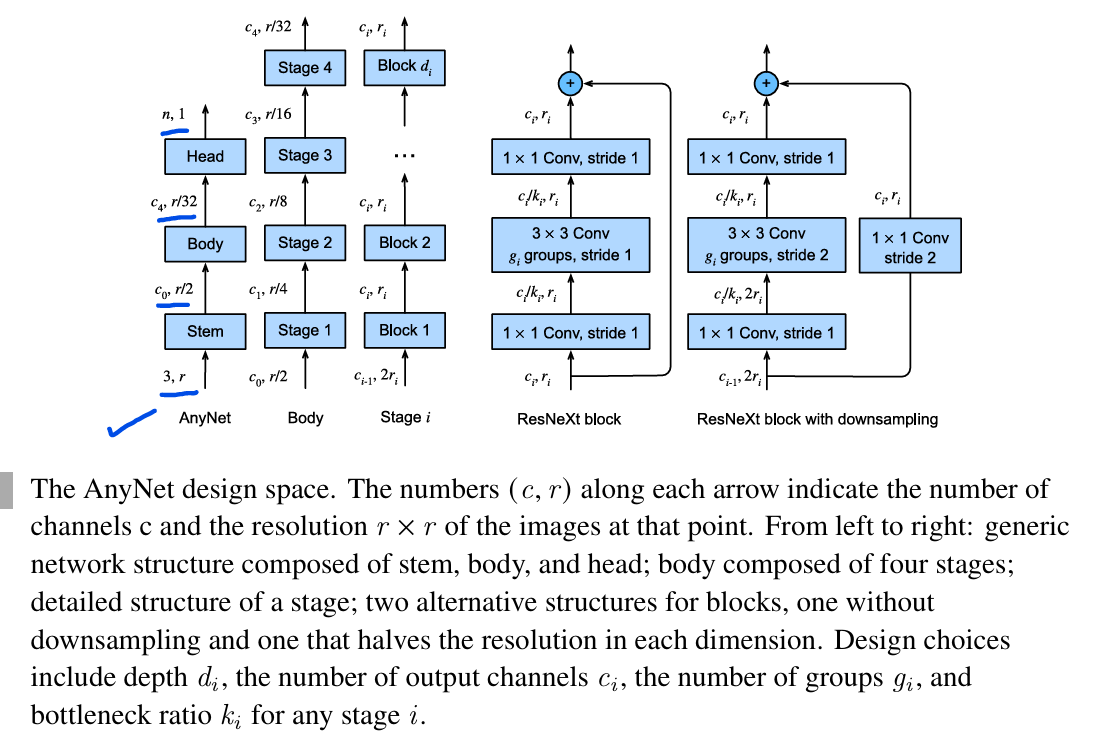

Just like an other modern convolution architecture, AnyNet uses a Stem, Body, and Head to partition the network into three distinct mathematical responsibilities.

The stem takes as its input RGB images using a 3x3 conv with a stride of 2, followed by Batch Norm, to halve the resolution from rxr to r/2xr/2.
It generates Co channels which are feed as input to body.

The body consist of 4 stages, where each stage i halves the resolution using a stride of 2 and produces Ci channels.
Each stage i consist of multiple blocks similar to ResNeXt blocks. The very first block in each stage is responsible for halving the resolution using a stride of 2. Each subsequent block within the stage leave the number of channels and resolution unchanged.

The head using GAP followed by FC to emit n dimensional vector.

Since we are using blocks similar to ResNeXt we need to pick number of groups gi for grouped convolution for each stage i.

This design leaves us with many configurable parameters:
- Block width (number of channels)
- Depth per stage (number of blocks per stage)
- Bottleneck ratio
- Groups width (g1, g2 ... g4)

In total this adds up to 17 parameters.



In [6]:
class AnyNet(d2l.Classifier):

    def __init__(self, arch, stem_channels, lr=0.1, num_classes=10):
        super(AnyNet, self).__init__()
        self.save_hyperparameters()

        self.net = nn.Sequential(self.stem(stem_channels))

        for i, s in enumerate(arch):
            self.net.add_module(f"stage{i+1}", self.stage(*s))

        self.net.add_module("head",
                            nn.Sequential(
                                nn.AdaptiveAvgPool2d((1,1)),
                                nn.Flatten(),
                                nn.LazyLinear(num_classes)
                            )
        )
        self.net.apply(d2l.init_cnn)

    def stem(self, num_channels):
        return nn.Sequential(
            nn.LazyConv2d(num_channels, kernel_size=3, stride=2, padding=1),
            nn.LazyBatchNorm2d(),
            nn.ReLU()
        )

    """
        depth - Number of blocks in ith stage
        num_channels - Number of channels in ith stage (Width of ith stage)
        groups - Number of groups in ith stage
        bot_mul - Bottleneck multiplier

        First block is responsible for halving the resolution
    """    
    def stage(self, depth, num_channels, groups, bot_mul):
        blk = []

        for i in range(depth):
            if i==0:
                blk.append(
                    d2l.ResNeXtBlock(
                        num_channels,
                        groups,
                        bot_mul,
                        use_1x1conv=True,
                        strides=2
                    )
                )
            else:
                blk.append(
                    d2l.ResNeXtBlock(
                        num_channels,
                        groups,
                        bot_mul,
                        use_1x1conv=False,
                        strides=1
                    )
                )
        return nn.Sequential(*blk)


### Reducing the design space

Since the number of configurable parameters is huge, it is computationally expensive to search over all possible architectures.

To reduce the design space, we can apply some assumptions:

- We assume that general design principles actually exist, so that many networks satisfying these requirements should offer good performance. Consequently, identifying a
distribution over networks can be a sensible strategy. In other words, we assume that
there are many good needles in the haystack.

- We need not train networks to convergence before we can assess whether a network is
good. Instead, it is sufficient to use the intermediate results as reliable guidance for
final accuracy. Using (approximate) proxies to optimize an objective is referred to as
multi-fidelity optimization (Forrester et al., 2007). Consequently, design optimization is
carried out, based on the accuracy achieved after only a few passes through the dataset,
reducing the cost significantly.

- Results obtained at asmaller scale (for smaller networks) generalize to larger ones. Con
sequently, optimization is carried out for networks that are structurally similar, but with
a smaller number of blocks, fewer channels, etc. Only in the end will we need to verify
that the so-found networks also offer good performance at scale.

- Aspects of the design can be approximately factorized so that it is possible to infer
their effect on the quality of the outcome somewhat independently. In other words, the
optimization problem is moderately easy.

These assumptions allow us to test many networks cheaply. In particular, we can sample uniformly from the space of configurations and evaluate their performance. Subsequently, we can evaluate the quality of the choice of parameters by reviewing the distribution of error/accuracy that can be achieved with said networks.

Denote by $F(e)$ the cumulative distribution function (CDF) for errors committed by networks of a given design space, drawn using probability distribution $p$. That is,

$$
F(e,p) \overset{\mathrm{def}}{=}
\mathbb{P}_{\text{net}\sim p}\{e(\text{net})\leq e\}.
\tag{8.8.1}
$$

Our goal is now to find a distribution $p$ over networks such that most networks have a very low error rate and where the support of $p$ is concise. Of course, this is computationally infeasible to perform accurately. We resort to a sample of networks

$$
Z \overset{\mathrm{def}}{=}
\{\text{net}_1,\ldots,\text{net}_n\}
$$

(with errors $e_1,\ldots,e_n$, respectively) from $p$ and use the empirical CDF $\hat{F}(e,Z)$ instead:

$$
\hat{F}(e,Z)=
\frac{1}{n}\sum_{i=1}^{n}\mathbf{1}(e_i\leq e).
\tag{8.8.2}
$$

Whenever the CDF for one set of choices majorizes (or matches) another CDF, it follows that its choice of parameters is superior (or indifferent).

Accordingly, Radosavovic et al. (2020) experimented with a shared network bottleneck ratio $k_i=k$ for all stages $i$ of the network. This gets rid of three of the four parameters governing the bottleneck ratio.

To assess whether this (negatively) affects the performance, one can draw networks from the constrained and from the unconstrained distribution and compare the corresponding CDFs. It turns out that this constraint does not affect the accuracy of the distribution of networks at all, as can be seen in the first panel of Fig. 8.8.2.

Likewise, we could choose to pick the same group width $g_i=g$ occurring at the various stages of the network. Again, this does not affect performance, as can be seen in the second panel of Fig. 8.8.2.

Both steps combined reduce the number of free parameters by six.

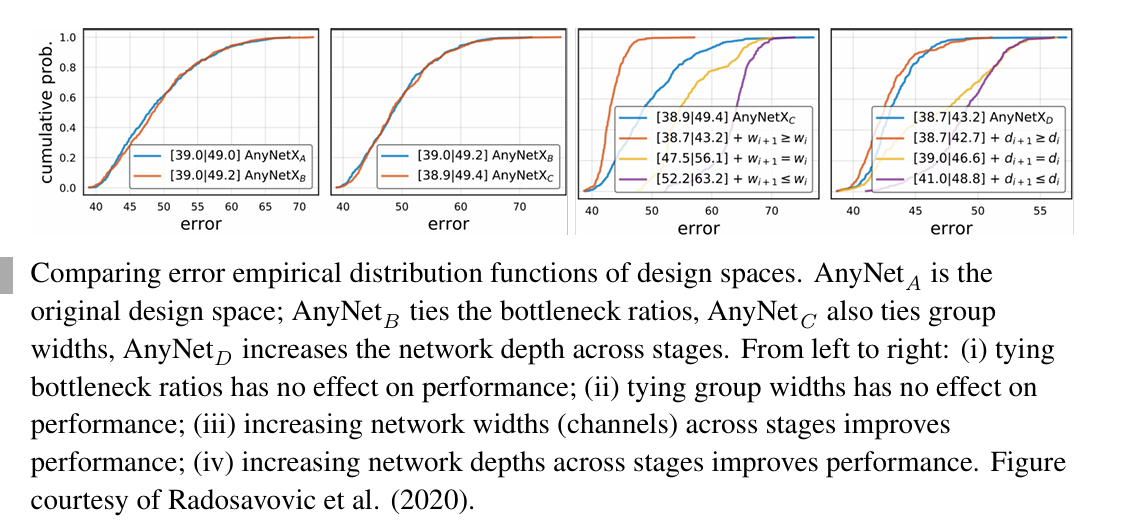

Next, we look for ways to reduce the multitude of potential choices for width and depth of the stages. It is a reasonable assumption that, as we go deeper, the number of channels should increase, i.e.,

$$
c_i \geq c_{i-1}
$$

($w_{i+1} \geq w_i$ per their notation in Fig. 8.8.2), yielding AnyNetX$_D$.

Likewise, it is equally reasonable to assume that as the stages progress, they should become deeper, i.e.,

$$
d_i \geq d_{i-1},
$$

yielding AnyNetX$_E$.

This can be experimentally verified in the third and fourth panels of Fig. 8.8.2, respectively.

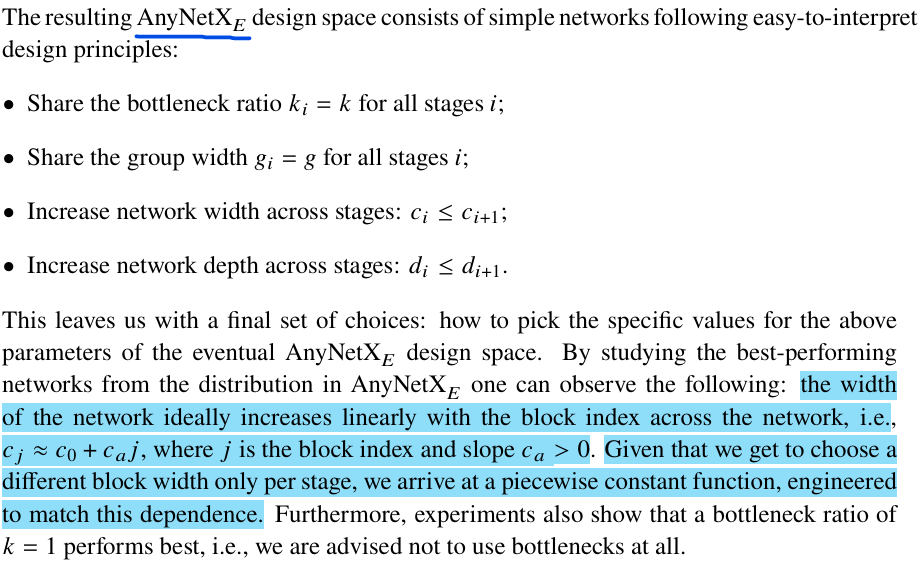

In [7]:
class RegNetX32(AnyNet):
    def __init__(self, lr=0.1, num_classes=10):
        stem_channels, groups, bot_mul = 32, 16, 1
        depths, channels = (4, 6), (32, 80)

        arch = []
        for d, c in zip(depths, channels):
            arch.append((d, c, groups, bot_mul))

        super().__init__(arch, stem_channels, lr, num_classes)

In [8]:
RegNetX32().layer_summary((1, 1, 96, 96))

Sequential output shape:	 torch.Size([1, 32, 48, 48])
Sequential output shape:	 torch.Size([1, 32, 24, 24])
Sequential output shape:	 torch.Size([1, 80, 12, 12])
Sequential output shape:	 torch.Size([1, 10])


In [ ]:
model = RegNetX32(lr=0.05)
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
data = d2l.FashionMNIST(batch_size=128, resize=(96, 96))
trainer.fit(model, data)